link walkthrough: https://docs.pytorch.org/tutorials/beginner/nn_tutorial.html

# some setups

In [1]:
from pathlib import Path
import requests

DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"

PATH.mkdir(parents=True, exist_ok=True)

URL = "https://github.com/pytorch/tutorials/raw/main/_static/"
FILENAME = "mnist.pkl.gz"

if not (PATH / FILENAME).exists():
        content = requests.get(URL + FILENAME).content
        (PATH / FILENAME).open("wb").write(content)

In [2]:
import pickle
import gzip

with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
        ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")

## vizualizare

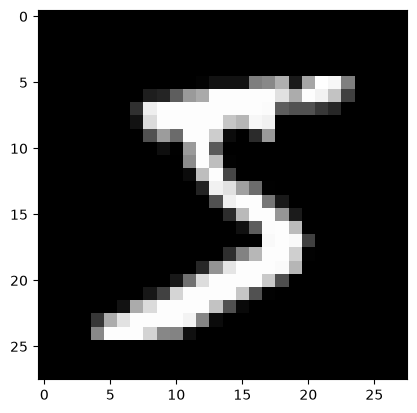

(50000, 784)


In [4]:
from matplotlib import pyplot as plt
import numpy as np

plt.imshow(x_train[0].reshape((28, 28)), cmap="gray")
plt.show()

print(x_train.shape)

## covertim la torch

In [6]:
import torch

x_train, y_train, x_valid, y_valid = map(
    torch.tensor, (x_train, y_train, x_valid, y_valid)
)
n, c = x_train.shape
print(x_train, y_train)
print(x_train.shape)
print(y_train.min(), y_train.max())

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]) tensor([5, 0, 4,  ..., 8, 4, 8])
torch.Size([50000, 784])
tensor(0) tensor(9)


# neural network from scratch!!

In [7]:
import math

weights = torch.randn(784, 10) / math.sqrt(784)
weights.requires_grad_()
bias = torch.zeros(10, requires_grad=True)

In [8]:
def log_softmax(x):
    return x - x.exp().sum(-1).log().unsqueeze(-1)

def model(xb):
    return log_softmax(xb @ weights + bias)

In [9]:
bs = 64

xb = x_train[0:bs]
preds = model(xb)
print(preds[0], preds.shape)

tensor([-2.3663, -2.2296, -2.5420, -2.6315, -2.5092, -1.8410, -2.2088, -2.1389,
        -2.1110, -2.8270], grad_fn=<SelectBackward0>) torch.Size([64, 10])


In [13]:
def nll(input, target):
    return -input[range(target.shape[0]), target].mean()

loss_func = nll

In [14]:
yb = y_train[0:bs]
print(loss_func(preds, yb))

tensor(2.2954, grad_fn=<NegBackward0>)


In [16]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds==yb).float().mean()

print(accuracy(preds, yb))

tensor(0.1094)


In [19]:
from IPython.core.debugger import set_trace

lr = 0.5
epochs = 2

for epoch in range(epochs):
    for i in range((n-1)//bs+1):
        start = i * bs
        end = start + bs
        xb = x_train[start:end]
        yb = y_train[start:end]

        preds = model(xb)
        loss = loss_func(preds, yb)

        loss.backward()
        with torch.no_grad():
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            weights.grad.zero_()
            bias.grad.zero_()

print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0647, grad_fn=<NegBackward0>) tensor(1.)


# FOLOSIM TORCH.NN ACUM!!

In [30]:
from torch import nn
import torch.nn.functional as F

loss_func = F.cross_entropy

def model(xb):
    return xb @ weights + bias

print(loss_func(preds, yb), accuracy(model(xb), yb))

tensor(0.2341, grad_fn=<NllLossBackward0>) tensor(1.)


In [31]:
class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__()
        self.lin = nn.Linear(784, 10)

    def forward(self, xb):
        return self.lin(xb)

model = Mnist_Logistic()
print(loss_func(model(xb), yb))

tensor(2.3518, grad_fn=<NllLossBackward0>)


In [33]:
def fit():
    for epoch in range(epochs):
        for i in range((n-1)//bs+1):
            start = i * bs
            end = start + bs
            xb = x_train[start:end]
            yb = y_train[start:end]
    
            preds = model(xb)
            loss = loss_func(preds, yb)
    
            loss.backward()
            with torch.no_grad():
                for p in model.parameters(): 
                    p -= p.grad * lr
                model.zero_grad()

fit()

In [34]:
print(loss_func(model(xb), yb))

tensor(0.0804, grad_fn=<NllLossBackward0>)


## acum cu torch.optim

In [36]:
from torch import optim

def get_model():
    model = Mnist_Logistic()
    return model, optim.SGD(model.parameters(), lr=lr)


model, opt = get_model()
print(loss_func(model(xb), yb))

for epoch in range(epochs):
    for i in range((n-1)//bs+1):
        start = i*bs
        end = start+bs
        xb = x_train[start : end]
        yb = y_train[start : end]
        preds = model(xb)
        loss = loss_func(preds, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(2.2935, grad_fn=<NllLossBackward0>)
tensor(0.0817, grad_fn=<NllLossBackward0>)


## acum cu Dataset

In [38]:
from torch.utils.data import TensorDataset

train_ds = TensorDataset(x_train, y_train)

model, opt = get_model()
for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        xb, yb = train_ds[i*bs : i*bs+bs]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))
        

tensor(0.0806, grad_fn=<NllLossBackward0>)


## acum cu DataLoader

In [41]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs)

model, opt = get_model()
for epoch in range(epochs):
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))
        

tensor(0.0813, grad_fn=<NllLossBackward0>)


# validationmaxxing

In [42]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs*2)

In [43]:
model, opt = get_model()

for epoch in range(epochs):
    model.train()
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        valid_loss = sum(loss_func(model(xb), yb) for xb, yb in valid_dl)

    print(epoch, valid_loss / len(valid_dl))
        

0 tensor(0.3066)
1 tensor(0.3617)
